# Four-target shortest paths: configurable training and automatic continuation

在第一个代码单元格修改 `EPOCHS`（目标累计轮数，例如 `30000`）和 `SEEDS`，然后按顺序运行。

- 已保存该预算的完整训练结果：打印 `[skip]`，直接复用验证集选出的 `best.pt`。
- 该预算尚未完成：搜索同一项目内、同一 seed、相同数据和超参数的 `latest.pt`，从不超过目标的最大已保存 epoch 继续。
- 没有可用的历史 checkpoint：从头训练。仅有 `best.pt` 不能证明训练预算完成，也不能精确恢复优化器。
- `EPOCHS` 是总目标，不是追加量；例如已保存 20000，设置 30000 就只再训练 10000。
- 每轮保存完整状态；中断后重复运行训练单元格即可。旧预算目录保留，新预算使用自己的目录。

原数据、MLP、采样、训练损失、优化器和评分保持原实现。这是上传的**整条路线 open-loop seed sweep**，不是近期的短窗口闭环模型。

**学习率说明：** 同一预算内恢复原余弦调度状态；修改目标预算并继续已有训练时，保留模型、优化器动量与随机状态，为剩余区间从 `learning_rate` 开启新一段余弦调度。因为旧余弦在预算末尾降到零，不能直接无限向后运行。这种分段续训与从第一轮就指定较大预算的单段余弦训练并不等价。比较不同预算时请记录这一点。

数据和验证 probe 仍固定。主分析使用训练/验证集；末尾独立 TEST 单元格只在需要最终评估时运行。


## 训练期间的完成率和选模

默认每 10 轮在验证集前 100 个布局上评估一次完成率；本次训练的首轮和最后一轮也会评估。`completion` 是这 100 个布局中全部访问四箱的比例；`visits` 是平均访问箱子数；无效数值轨迹计为失败。使用 RK4 1000 步、float64、连续线段到目标的距离，与主验证评估一致。它不是全验证集或 TEST 完成率。

`CHECKPOINT_SELECTION = "completion"` 默认按 **完成率高者优先，持平时最优访问顺序成功率高者优先，再持平时验证 MSE 低者优先**，保存在 `best_completion.pt`；主结果与最终 TEST 都使用它。`best.pt` 继续保存最低验证 MSE 的模型，确保原续训逻辑和旧模型可用。设为 `"mse"` 可以恢复原来的报告选模方式。训练的损失函数始终是原 MSE，没有改成强化学习或完成率损失。

完成率历史保存在每个 run 的 `completion_history.json`。续训会继承之前的完成率最佳模型。已有训练预算不会重训，仅对已保存的最低 MSE 模型和最后一轮模型补测，并与已有完成率模型比较；无法回溯没有保存的历史模型。改选模规则后，结果应标明使用哪一种 checkpoint。

**当前访问容差统一为 0.02：** 训练监测、主验证和末尾独立 TEST 均使用 0.02。日志显示 `selected_epoch`、`BEST COMPLETION` 百分数与 `BEST OPTIMAL` 百分数，不显示最佳 MSE。实际评估选择以最后 `[selected for evaluation]` 行和 `selection_record.json` 为准。


## 最优访问顺序（optimal）

日志 `optimal` 表示：全部评估布局中，完成四箱访问且首次访问顺序对应中心最短路线的比例。例如 100 个布局，80 个完成，其中 60 个顺序最优，则 completion=80%、optimal=60%。不加入次优/near-opt 指标或示范。

访问仍按路径线段进入半径 0.02 的圆判断；同一控制线段内经过多个目标时按实际进入圆的先后排序。评估时枚举 24 种中心路线，接受并列最优，数值比较容差 rtol=1e-6、atol=1e-9。最短路计算仅用于评分，不向策略提供答案。

**顺序最优不保证实际曲线最短。** 此 optimal 指标不对曲线绕路作最优性承诺。

选模规则现在为 `(completion_percent, optimal_order_success_percent, -validation_mse)`；训练损失仍为原 MSE。新增版本标记使旧的两项评分和不含 optimal 的缓存自动失效，现存 MSE-best、latest 和旧 completion-best 会重新评分。已有训练无需重训，但没有保存的历史权重不能回溯重选。


In [1]:
from pathlib import Path
import copy
import itertools
import hashlib
import json
import random
import subprocess
import sys
import platform
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from IPython.display import display, Markdown


# ============================================================
# Portable project-root discovery
# ============================================================

def find_project_root(start=None):
    """
    Find the Git repository root automatically.

    The repository may live anywhere on any computer. The only
    requirement is that this notebook is run with a working directory
    somewhere inside the streaming-flow-policy repository.
    """
    start = Path.cwd() if start is None else Path(start)
    start = start.expanduser().resolve()

    # First try Git itself.
    try:
        result = subprocess.run(
            ["git", "-C", str(start), "rev-parse", "--show-toplevel"],
            check=True,
            capture_output=True,
            text=True,
        )
        root = Path(result.stdout.strip()).resolve()
        if (root / "pyproject.toml").exists():
            return root
    except (subprocess.CalledProcessError, FileNotFoundError):
        pass

    # Fallback: walk upward and look for repository markers.
    for candidate in [start, *start.parents]:
        if (
            (candidate / "pyproject.toml").exists()
            and (
                candidate
                / "experiments"
                / "four_boxes_experiments"
                / "four_targets"
            ).exists()
        ):
            return candidate

    raise RuntimeError(
        "Could not locate the streaming-flow-policy repository root. "
        "Run this notebook from a working directory inside the repository."
    )


PROJECT_ROOT = find_project_root()

TASK_ROOT = (
    PROJECT_ROOT
    / "experiments"
    / "four_boxes_experiments"
    / "four_targets"
)

DATASET_DIR = TASK_ROOT / "datasets" / "v1"

SWEEP_ROOT = (
    TASK_ROOT
    / "runs"
    / "conditional_mlp_canonical_fresh_002"
)

SWEEP_ROOT.mkdir(parents=True, exist_ok=True)

# Compatible legacy seed-0 runs are discovered automatically.

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# ============================================================
# Load fixed dataset
# ============================================================

required = [
    DATASET_DIR / "config.json",
    DATASET_DIR / "train.npz",
    DATASET_DIR / "validation.npz",
]

missing = [
    str(path)
    for path in required
    if not path.exists()
]

if missing:
    raise FileNotFoundError(
        "Required dataset files are missing:\n"
        + "\n".join(missing)
    )


splits = {}

for name in ["train", "validation"]:
    with np.load(
        DATASET_DIR / f"{name}.npz",
        allow_pickle=False,
    ) as archive:
        splits[name] = {
            key: archive[key].copy()
            for key in archive.files
        }

    split = splits[name]
    n = len(split["targets"])

    for key, shape in {
        "starts": (n, 2),
        "targets": (n, 4, 2),
        "conditions": (n, 10),
        "routes": (n, 5, 2),
        "knot_tau": (n, 5),
        "lengths": (n,),
    }.items():
        assert split[key].shape == shape, (
            name,
            key,
            split[key].shape,
        )
        assert np.isfinite(split[key]).all(), (
            name,
            key,
        )

    assert np.all(
        np.diff(split["knot_tau"], axis=1) > 0
    )

    np.testing.assert_allclose(
        split["knot_tau"][:, 0],
        0,
    )

    np.testing.assert_allclose(
        split["knot_tau"][:, -1],
        1,
    )

    np.testing.assert_array_equal(
        split["conditions"],
        np.concatenate(
            [
                split["starts"],
                split["targets"].reshape(n, 8),
            ],
            axis=1,
        ),
    )

    np.testing.assert_array_equal(
        split["routes"][:, 0],
        split["starts"],
    )


assert len(splits["train"]["targets"]) == 10_000
assert len(splits["validation"]["targets"]) == 1_000


# ============================================================
# Portable dataset fingerprint
# ============================================================

def sha256(path):
    digest = hashlib.sha256()

    with path.open("rb") as stream:
        for block in iter(
            lambda: stream.read(1024 * 1024),
            b"",
        ):
            digest.update(block)

    return digest.hexdigest()


# Only fingerprint the actual numerical training/validation data.
# config.json is metadata and is intentionally not part of the
# experiment identity.
DATA_FILES = [
    DATASET_DIR / "train.npz",
    DATASET_DIR / "validation.npz",
]

DATASET_SHA256 = {
    path.name: sha256(path)
    for path in DATA_FILES
}


# ============================================================
# Experiment settings
# ============================================================

# Target TOTAL epochs. Increase this number to continue existing training.
EPOCHS = 20000
if not isinstance(EPOCHS, int) or isinstance(EPOCHS, bool) or EPOCHS <= 0:
    raise ValueError("EPOCHS must be a positive integer.")
BUDGETS = [EPOCHS]  # Optional: [5000, 10000, 20000]; processed in ascending order.
SEEDS = [0]

# Completion monitoring: same first 100 validation layouts as the main analysis.
# Monitoring and main validation use 0.02; the optional TEST cell also uses 0.02.
MONITOR = dict(every=10, layouts=100, ode_steps=1000, visit_tolerance=0.02)
# Versioning invalidates older cached metrics without changing training identity.
MONITOR.update(metrics_version="completion_optimal_order_v1", optimal_order_rtol=1e-6)
CHECKPOINT_SELECTION = "completion"  # completion -> optimal order -> MSE; or "mse"
assert CHECKPOINT_SELECTION in ("completion", "mse")
assert all(isinstance(MONITOR[k], int) and MONITOR[k] > 0
           for k in ("every", "layouts", "ode_steps"))
assert MONITOR["visit_tolerance"] > 0

BASE_CONFIG = {
    "input_preprocessing":
        "sort_targets_by_x_then_y",
    "num_training_layouts":
        10_000,
    "validation_probe_seed":
        500,
    "validation_probe_size":
        20_000,
    "steps_per_epoch":
        100,
    "batch_size":
        2048,
    "learning_rate":
        1e-3,
    "weight_decay":
        1e-6,
    "hidden_dim":
        128,
    "num_hidden_layers":
        4,
    "sigma_0":
        0.05,
    "stabilizing_gain":
        2.5,
    "dataset_sha256":
        DATASET_SHA256,
}

# sample_batch() reads CONFIG, so this global is replaced with the
# current run's configuration immediately before training.
CONFIG = dict(BASE_CONFIG)


print("Project root:", PROJECT_ROOT)
print("Dataset dir:", DATASET_DIR)
print("Device:", DEVICE)
print("Budgets:", BUDGETS)
print("Seeds:", SEEDS)
print(
    "Layouts:",
    {
        key: len(value["targets"])
        for key, value in splits.items()
    },
)
print("Sweep output:", SWEEP_ROOT)
print("Dataset fingerprint:", DATASET_SHA256)
print("Test split has not been loaded.")


Project root: /home/matcho/projects/streaming-flow-policy
Dataset dir: /home/matcho/projects/streaming-flow-policy/experiments/four_boxes_experiments/four_targets/datasets/v1
Device: cuda
Budgets: [20000]
Seeds: [0]
Layouts: {'train': 10000, 'validation': 1000}
Sweep output: /home/matcho/projects/streaming-flow-policy/experiments/four_boxes_experiments/four_targets/runs/conditional_mlp_canonical_fresh_002
Dataset fingerprint: {'train.npz': '0fb20f206750157be80ac9281378f07c684a1d6d538d9c035114e78dfb3e70fa', 'validation.npz': '2eb47a32c8c8b24f1d0babe87fa7fbd87826196051281cd73fc464eab88268e7'}
Test split has not been loaded.


## Reusable model and sampling definitions


In [2]:
def canonicalize_box_inputs(inputs):
    boxes = inputs[:, 5:].reshape(-1, 4, 2)
    for coordinate in [1, 0]:  # secondary y key, then primary x key
        order = torch.argsort(boxes[:, :, coordinate], dim=1, stable=True)
        boxes = torch.gather(boxes, 1, order.unsqueeze(-1).expand(-1, -1, 2))
    return torch.cat([inputs[:, :5], boxes.reshape(-1, 8)], dim=1)

class CanonicalConditionalVelocityMLP(nn.Module):
    def __init__(self):
        super().__init__()
        layers = []
        width = 13
        for _ in range(4):
            layers.extend([nn.Linear(width, 128), nn.SiLU()])
            width = 128
        layers.append(nn.Linear(width, 2))
        self.network = nn.Sequential(*layers)

    def forward(self, inputs):
        return self.network(2.0 * canonicalize_box_inputs(inputs) - 1.0)


def sample_batch(split, batch_size, rng):
    indices = rng.integers(0, len(split["targets"]), size=batch_size)
    tau = rng.uniform(0.0, 1.0, size=batch_size)
    routes = split["routes"][indices]
    knots = split["knot_tau"][indices]
    segments = np.clip((tau[:, None] >= knots[:, 1:]).sum(axis=1), 0, 3)
    rows = np.arange(batch_size)
    p0, p1 = routes[rows, segments], routes[rows, segments + 1]
    t0 = knots[rows, segments]
    interval = knots[rows, segments + 1] - t0
    positions = p0 + ((tau - t0) / interval)[:, None] * (p1 - p0)
    derivatives = (p1 - p0) / interval[:, None]
    offsets = (CONFIG["sigma_0"] * np.exp(-CONFIG["stabilizing_gain"] * tau))[:, None] * rng.standard_normal((batch_size, 2))
    actions = positions + offsets
    targets = derivatives - CONFIG["stabilizing_gain"] * offsets
    inputs = np.concatenate([actions, tau[:, None], split["conditions"][indices]], axis=1)
    return inputs.astype(np.float32), targets.astype(np.float32)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def atomic_save(payload, path):
    temporary = path.with_suffix(".tmp")
    torch.save(payload, temporary)
    temporary.replace(path)


@torch.no_grad()
def probe_mse(model, inputs, targets):
    model.eval()
    total = 0.0
    for offset in range(0, len(inputs), 4096):
        x, y = inputs[offset:offset+4096], targets[offset:offset+4096]
        loss = nn.functional.mse_loss(model(x), y)
        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite validation loss")
        total += loss.item() * len(x)
    return total / len(inputs)


def target_distances(path, targets):
    p0, vectors = path[:-1], np.diff(path, axis=0)
    offsets = targets[:, None, :] - p0[None, :, :]
    denominator = np.maximum(np.sum(vectors**2, axis=1), 1e-30)
    fraction = np.clip(np.sum(offsets*vectors[None, :, :], axis=-1) / denominator[None, :], 0, 1)
    nearest = p0[None, :, :] + fraction[:, :, None]*vectors[None, :, :]
    return np.linalg.norm(targets[:, None, :] - nearest, axis=-1).min(axis=1)



def four_target_path_metrics(paths, split, visit_tolerance, valid=None,
                             optimal_rtol=1e-6):
    """Completion and optimal FIRST-VISIT ORDER, not shortest executed curves.

    First visits use continuous segment/circle entry times. Enumerate all 24
    center routes offline, accepting tied optima. Simultaneous first visits may
    be ordered either way; take the shortest center order consistent with times.
    """
    paths = np.asarray(paths, dtype=np.float64)
    targets = np.asarray(split["targets"], dtype=np.float64)
    starts = np.asarray(split["starts"], dtype=np.float64)
    n = len(paths)
    if paths.ndim != 3 or paths.shape[1] < 1 or paths.shape[2] != 2:
        raise ValueError("paths must have shape (layouts, >=1 positions, 2)")
    if targets.shape != (n, 4, 2) or starts.shape != (n, 2):
        raise ValueError("Expected exactly four targets per layout")
    finite = np.isfinite(paths).all(axis=(1, 2))
    valid = finite if valid is None else np.asarray(valid, dtype=bool) & finite
    permutations = np.asarray(list(itertools.permutations(range(4))), dtype=np.int64)
    first_times = np.full((n, 4), np.inf)
    orders = np.full((n, 4), -1, dtype=np.int64)
    optimal_lengths = np.empty(n)
    order_lengths = np.full(n, np.nan)
    for i, path in enumerate(paths):
        # Exact center-route optimum is evaluation-only information.
        routes = np.concatenate([np.broadcast_to(starts[i], (24, 1, 2)),
                                 targets[i][permutations]], axis=1)
        lengths = np.linalg.norm(np.diff(routes, axis=1), axis=-1).sum(axis=1)
        optimal_lengths[i] = lengths.min()
        inside = np.linalg.norm(targets[i] - path[0], axis=-1) <= visit_tolerance
        first_times[i, inside] = 0.
        if len(path) > 1 and finite[i]:
            delta = np.diff(path, axis=0)
            offset = path[:-1, None, :] - targets[i][None, :, :]
            aa = np.sum(delta*delta, axis=-1)[:, None]
            bb = 2*np.sum(offset*delta[:, None, :], axis=-1)
            cc = np.sum(offset*offset, axis=-1) - visit_tolerance**2
            disc = bb*bb - 4*aa*cc
            denom = np.where(aa > 1e-24, 2*aa, 1.)
            entry = (-bb - np.sqrt(np.maximum(disc, 0.))) / denom
            crosses = ((aa > 1e-24) & (disc >= 0.)
                       & (entry >= -1e-10) & (entry <= 1+1e-10))
            fractions = np.where(cc <= 0., 0.,
                                 np.where(crosses, np.clip(entry, 0., 1.), np.inf))
            times = np.arange(len(delta))[:, None] + fractions
            first_times[i] = np.minimum(first_times[i], times.min(axis=0))
        if np.isfinite(first_times[i]).all():
            time_orders = first_times[i][permutations]
            consistent = (np.diff(time_orders, axis=1) >= -1e-10).all(axis=1)
            index = np.argmin(np.where(consistent, lengths, np.inf))
            orders[i] = permutations[index]
            order_lengths[i] = lengths[index]
    visited_counts = np.isfinite(first_times).sum(axis=1)
    completed = (visited_counts == 4) & valid
    optimal_success = completed & np.isclose(order_lengths, optimal_lengths,
                                             rtol=optimal_rtol, atol=1e-9)
    summary = dict(completion_percent=float(100*np.mean(completed)),
                   optimal_order_success_percent=float(100*np.mean(optimal_success)),
                   mean_visited=float(visited_counts.mean()),
                   invalid_count=int((~valid).sum()), layouts=int(n))
    details = dict(first_visit_times=first_times, visited_order=orders,
                   visited_counts=visited_counts, completed=completed,
                   optimal_order_success=optimal_success,
                   center_order_length=order_lengths, center_optimal_length=optimal_lengths)
    return summary, details


## Train / resume requested total epochs

同一 seed 固定模型初始化和训练采样随机种子，验证 probe 始终使用 seed 500。

训练前先检查目标预算是否完成，再寻找最大可用保存轮数。进度依据 `latest.pt["epoch"]`，不是 `best.pt["epoch"]`：最佳模型可能来自更早的一轮。

自动搜索当前 sweep、旧 `conditional_mlp_canonical_seed_sweep`、`conditional_mlp_canonical_seed_sweep_20000` 以及旧 seed-0 独立目录。只复用数据指纹与数值超参数一致的记录，不把超过目标轮数的模型当作较早预算的结果。

同预算中断会恢复调度器；延长预算会明确打印新增余弦区间。请复制完整 run 文件夹（包括 latest.pt 和 best.pt）以便跨机器续训。

训练日志新增 `completion`、`visits`、`invalid` 和当前选模方式。完成率是实际 rollout 的任务结果，验证 MSE 是速度拟合误差。默认每 10 轮进行一次 rollout，所以会比只计算损失更耗时；可修改 `MONITOR["every"]`。

日志包含 `optimal` 和 `BEST OPTIMAL`，前者是当前模型的最优顺序成功率，后者是当前选中模型的对应成功率。两者分母都是全部监测布局。


In [3]:
def completion_score(summary, validation_loss):
    # Lexicographic: completion, completed optimal first-visit order, lower MSE.
    return (float(summary["completion_percent"]),
            float(summary["optimal_order_success_percent"]), -float(validation_loss))


def atomic_json_record(path, payload):
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(payload, indent=2), encoding="utf-8")
    temporary.replace(path)


@torch.no_grad()
def measure_completion(model):
    """Fixed validation subset; RK4 and continuous-segment target distances.

    Double precision matches the notebook's main validation evaluation. The
    deep copy avoids changing training weights, precision, mode or RNG state.
    Invalid trajectories are counted as failures, not allowed to abort training.
    """
    count = min(MONITOR["layouts"], len(splits["validation"]["targets"]))
    split = {key: value[:count] for key, value in splits["validation"].items()}
    evaluation_model = copy.deepcopy(model).to(dtype=torch.float64)
    evaluation_model.eval()
    parameter = next(evaluation_model.parameters())
    conditions = torch.as_tensor(split["conditions"], dtype=parameter.dtype, device=parameter.device)
    actions = torch.as_tensor(split["starts"], dtype=parameter.dtype, device=parameter.device).clone()
    valid = torch.ones(count, dtype=torch.bool, device=parameter.device)
    paths = [actions.cpu().numpy().copy()]
    steps = MONITOR["ode_steps"]
    dt = 1.0 / steps
    def velocity(a, tau):
        t = torch.full((len(a), 1), tau, dtype=a.dtype, device=a.device)
        return evaluation_model(torch.cat([a, t, conditions], dim=1))
    for step in range(steps):
        tau = step * dt
        k1 = velocity(actions, tau)
        k2 = velocity(actions + dt*k1/2, tau + dt/2)
        k3 = velocity(actions + dt*k2/2, tau + dt/2)
        k4 = velocity(actions + dt*k3, min(tau + dt, 1.0))
        proposed = actions + dt/6 * (k1 + 2*k2 + 2*k3 + k4)
        valid &= torch.isfinite(proposed).all(dim=1)
        actions = torch.where(valid[:, None], proposed, actions)
        paths.append(actions.cpu().numpy().copy())
    paths = np.stack(paths, axis=1)
    summary, _ = four_target_path_metrics(
        paths, split, MONITOR["visit_tolerance"], valid=valid.cpu().numpy(),
        optimal_rtol=MONITOR["optimal_order_rtol"])
    del evaluation_model
    return summary


def record_completion(model, epoch, validation_loss, run_dir):
    history_path = run_dir / "completion_history.json"
    record = dict(monitor_spec=copy.deepcopy(MONITOR), records=[])
    if history_path.exists():
        saved = json.loads(history_path.read_text(encoding="utf-8"))
        if saved.get("monitor_spec") == MONITOR:
            record = saved
    cached = next((row for row in record["records"] if row["epoch"] == int(epoch)), None)
    if cached is None:
        summary = measure_completion(model)
        cached = dict(epoch=int(epoch), validation_loss=float(validation_loss), **summary)
        record["records"].append(cached)
        record["records"].sort(key=lambda row: row["epoch"])
        atomic_json_record(history_path, record)
    summary = {key: cached[key] for key in (
        "completion_percent", "optimal_order_success_percent", "mean_visited", "invalid_count", "layouts")}
    best_path = run_dir / "best_completion.pt"
    best = load_own_checkpoint(best_path) if best_path.exists() else None
    if best is not None:
        assert_same_experiment(best["config"], CONFIG, best_path)
    compatible = (best is not None and best.get("monitor_spec") == MONITOR
                  and len(best.get("completion_score", ())) == 3)
    if not compatible or completion_score(summary, validation_loss) > tuple(best["completion_score"]):
        state = {name: tensor.detach().cpu().clone()
                 for name, tensor in model.state_dict().items()}
        best = dict(model=state, epoch=int(epoch), validation_loss=float(validation_loss),
                    config=copy.deepcopy(CONFIG), monitor_spec=copy.deepcopy(MONITOR),
                    completion_summary=summary,
                    completion_score=completion_score(summary, validation_loss))
        atomic_save(best, best_path)
    return summary, best


def inherit_completion_records(source_dir, run_dir, start_epoch, source_checkpoint=None):
    """Keep earlier candidates when extending a budget or recovering an interruption."""
    if source_dir is None:
        return
    old_history = source_dir / "completion_history.json"
    if old_history.exists():
        history = json.loads(old_history.read_text(encoding="utf-8"))
        if history.get("monitor_spec") == MONITOR:
            history["records"] = [row for row in history["records"] if row["epoch"] <= start_epoch]
            atomic_json_record(run_dir / "completion_history.json", history)
    old_best = source_dir / "best_completion.pt"
    embedded = (source_checkpoint or {}).get("completion_best_checkpoint")
    disk = load_own_checkpoint(old_best) if old_best.exists() else None
    candidates = [c for c in (disk, embedded)
                  if c is not None and int(c["epoch"]) <= start_epoch]
    for candidate in candidates:
        assert_same_experiment(candidate["config"], CONFIG, old_best)
    compatible = [c for c in candidates if c.get("monitor_spec") == MONITOR
                  and len(c.get("completion_score", ())) == 3]
    if compatible:
        candidate = max(compatible, key=lambda c: tuple(c["completion_score"]))
    else:
        # Prefer the on-disk selection, which may have been re-scored after
        # training finished without rewriting latest.pt's embedded snapshot.
        candidate = candidates[0] if candidates else None
    if candidate is not None:
        atomic_save(dict(candidate, config=copy.deepcopy(CONFIG)), run_dir / "best_completion.pt")
    elif disk is not None and source_dir == run_dir and int(disk["epoch"]) > start_epoch:
        old_best.replace(run_dir / f"best_completion_uncommitted_epoch_{disk['epoch']}.pt")


def choose_report_checkpoint(run_dir, mse_checkpoint, latest_checkpoint=None):
    """Old completed runs: compare only saved MSE-best/latest states, never retrain."""
    latest_path = run_dir / "latest.pt"
    candidates = [(mse_checkpoint["epoch"], mse_checkpoint["model"],
                   mse_checkpoint["validation_loss"])]
    if latest_checkpoint is not None or latest_path.exists():
        latest = latest_checkpoint if latest_checkpoint is not None else load_own_checkpoint(latest_path)
        candidates.append((latest["epoch"], latest["model"],
                           latest["history"]["validation_loss"][-1]))
    # Capture old completion-best weights BEFORE record_completion replaces
    # their old-rule file. Include embedded snapshots when upgrading old runs.
    previous_path = run_dir / "best_completion.pt"
    previous = load_own_checkpoint(previous_path) if previous_path.exists() else None
    if previous is not None:
        assert_same_experiment(previous["config"], CONFIG, previous_path)
        candidates.append((previous["epoch"], previous["model"], previous["validation_loss"]))
    if latest_checkpoint is not None:
        previous = latest_checkpoint.get("completion_best_checkpoint")
        if previous is not None:
            candidates.append((previous["epoch"], previous["model"], previous["validation_loss"]))
    # No model initialization on training's RNG stream.
    rng_state = torch.get_rng_state()
    try:
        model = CanonicalConditionalVelocityMLP().to(device=DEVICE, dtype=torch.float32)
    finally:
        torch.set_rng_state(rng_state)
    seen = set()
    for epoch, state, loss in candidates:
        if int(epoch) in seen:
            continue
        seen.add(int(epoch))
        model.load_state_dict(state)
        summary, best = record_completion(model, epoch, loss, run_dir)
        print(f"[completion] epoch {epoch}: completion={summary['completion_percent']:.2f}% "
              f"| optimal={summary['optimal_order_success_percent']:.2f}% "
              f"| visits={summary['mean_visited']:.2f}/4 | "
              f"BEST COMPLETION={best['completion_summary']['completion_percent']:.2f}% | "
              f"BEST EPOCH={best['epoch']} (fixed validation subset)")
    del model
    selected = best if CHECKPOINT_SELECTION == "completion" else mse_checkpoint
    filename = "best_completion.pt" if CHECKPOINT_SELECTION == "completion" else "best.pt"
    selection_record = dict(selection=CHECKPOINT_SELECTION, epoch=int(selected["epoch"]),
                            validation_mse=float(selected["validation_loss"]),
                            checkpoint_path=str((run_dir / filename).resolve()),
                            completion_best_epoch=int(best["epoch"]),
                            completion_best_percent=float(best["completion_summary"]["completion_percent"]),
                            completion_best_mse=float(best["validation_loss"]),
                            completion_best_optimal_percent=float(best["completion_summary"]["optimal_order_success_percent"]),
                            selection_order=["completion", "optimal_order_success", "lower_validation_mse"])
    atomic_json_record(run_dir / "selection_record.json", selection_record)
    print(f"[selected for evaluation] rule={CHECKPOINT_SELECTION} | "
          f"epoch={selected['epoch']} | "
          f"BEST COMPLETION={best['completion_summary']['completion_percent']:.2f}% | "
          f"BEST OPTIMAL={best['completion_summary']['optimal_order_success_percent']:.2f}% | "
          f"checkpoint={run_dir / filename}")
    return selected


def normalized_experiment_config(config):
    cfg = copy.deepcopy(config)
    # A requested stopping epoch is not the experiment's numerical identity.
    for key in ("dataset_dir", "experiment", "num_epochs"):
        cfg.pop(key, None)
    if "dataset_sha256" in cfg:
        hashes = cfg["dataset_sha256"]
        cfg["dataset_sha256"] = {
            name: hashes[name] for name in ("train.npz", "validation.npz")
            if name in hashes
        }
    return cfg


def assert_same_experiment(saved_config, current_config, source):
    saved = normalized_experiment_config(saved_config)
    current = normalized_experiment_config(current_config)
    if saved != current:
        differences = [
            f"{key}: saved={saved.get(key, '<missing>')!r}; "
            f"current={current.get(key, '<missing>')!r}"
            for key in sorted(set(saved) | set(current))
            if saved.get(key, '<missing>') != current.get(key, '<missing>')
        ]
        raise ValueError(f"Experiment configuration differs: {source}\n"
                         + "\n".join(differences))


def make_run_config(budget, seed):
    cfg = copy.deepcopy(BASE_CONFIG)
    cfg.update(experiment=f"full_dataset_canonical_budget_{budget}_seed_{seed}",
               training_seed=int(seed), train_sampling_seed=int(1000 + seed),
               num_epochs=int(budget))
    return cfg


def load_own_checkpoint(path):
    return torch.load(path, map_location="cpu", weights_only=True)


def checkpoint_directories(seed):
    return sorted(
        SWEEP_ROOT.glob(f"budget_*_seed_{seed}")
    )


def completed_checkpoint(run_dir, budget, config):
    """Only a completed latest checkpoint / history can prove a budget is done.

    best.pt's epoch is the validation-selected epoch, NOT training progress.
    """
    best_path = run_dir / "best.pt"
    if not best_path.exists():
        return None
    latest_path = run_dir / "latest.pt"
    if latest_path.exists():
        latest = load_own_checkpoint(latest_path)
        if normalized_experiment_config(latest.get("config", {})) != normalized_experiment_config(config):
            return None
        assert_same_experiment(latest["config"], config, latest_path)
        # A later budget's best must never masquerade as an earlier snapshot.
        if (int(latest["epoch"]) != budget
                or int(latest["config"]["num_epochs"]) != budget):
            return None
    else:
        # Read-only support for old runs that retained best.pt + full history.
        history_path = run_dir / "history.json"
        if not history_path.exists():
            return None
        history = json.loads(history_path.read_text(encoding="utf-8"))
        if (len(history.get("train_loss", [])) != budget
                or len(history.get("validation_loss", [])) != budget):
            return None
    checkpoint = load_own_checkpoint(best_path)
    if normalized_experiment_config(checkpoint.get("config", {})) != normalized_experiment_config(config):
        return None
    assert_same_experiment(checkpoint["config"], config, best_path)
    if (int(checkpoint["config"]["num_epochs"]) != budget
            or not 1 <= int(checkpoint["epoch"]) <= budget):
        return None
    return checkpoint


def select_resume_source(budget, seed, config):
    """Choose the furthest compatible saved epoch not beyond the target."""
    required = {"model", "optimizer", "scheduler", "epoch", "history",
                "best_loss", "best_epoch", "numpy_rng_state", "torch_rng_state"}
    candidates = []
    for directory in checkpoint_directories(seed):
        path = directory / "latest.pt"
        if not path.exists():
            continue
        saved = load_own_checkpoint(path)
        if normalized_experiment_config(saved.get("config", {})) != normalized_experiment_config(config):
            continue
        epoch = int(saved["epoch"])
        if epoch > budget:
            continue
        missing = required - set(saved)
        if missing:
            raise RuntimeError(f"Cannot resume {path}; missing state: {sorted(missing)}")
        best_path = directory / "best.pt"
        if not best_path.exists():
            raise FileNotFoundError(f"Copy the complete run folder; missing {best_path}")
        candidates.append((epoch, directory))
    if not candidates:
        return None
    # Prefer this target's existing partial run when saved epochs tie.
    expected = SWEEP_ROOT / f"budget_{budget}_seed_{seed}"
    return max(candidates, key=lambda item: (item[0], item[1] == expected))[1]


def train_or_resume_run_mse(budget, seed):
    global CONFIG
    CONFIG = make_run_config(budget, seed)
    run_dir = SWEEP_ROOT / f"budget_{budget}_seed_{seed}"

    if (run_dir / "config.json").exists():
        assert_same_experiment(json.loads((run_dir / "config.json").read_text(
            encoding="utf-8")), CONFIG, run_dir / "config.json")

    # Check the requested budget BEFORE constructing any model or optimizer.
    directories = [run_dir] + [p for p in checkpoint_directories(seed) if p != run_dir]
    for directory in directories:
        selected = completed_checkpoint(directory, budget, CONFIG)
        if selected is not None:
            print(f"[skip] seed {seed}: {budget} epochs already completed; "
                  f"{directory}; report selection follows")
            return directory, selected

    source_dir = select_resume_source(budget, seed, CONFIG)
    if source_dir is None and (run_dir / "best.pt").exists():
        raise RuntimeError(f"{run_dir} has best.pt but no usable full checkpoint. "
                           "Restore latest.pt to resume; best weights alone do not "
                           "contain optimizer and random-number states.")

    set_seed(CONFIG["training_seed"])
    model = CanonicalConditionalVelocityMLP().to(device=DEVICE, dtype=torch.float32)
    optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG["learning_rate"],
                                 weight_decay=CONFIG["weight_decay"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=budget)
    train_rng = np.random.default_rng(CONFIG["train_sampling_seed"])
    history = {"train_loss": [], "validation_loss": []}
    best_loss, best_epoch, start_epoch = float("inf"), None, 0
    scheduler_segment = {"start_epoch": 0, "end_epoch": budget}
    best_checkpoint = None

    if source_dir is not None:
        latest_path = source_dir / "latest.pt"
        ckpt = load_own_checkpoint(latest_path)
        assert_same_experiment(ckpt["config"], CONFIG, latest_path)
        model.load_state_dict(ckpt["model"])
        optimizer.load_state_dict(ckpt["optimizer"])
        scheduler.load_state_dict(ckpt["scheduler"])
        start_epoch = int(ckpt["epoch"])
        train_rng.bit_generator.state = ckpt["numpy_rng_state"]
        torch.set_rng_state(ckpt["torch_rng_state"].cpu())
        if "python_rng_state" in ckpt:
            random.setstate(ckpt["python_rng_state"])
        if DEVICE.type == "cuda":
            for i, state in enumerate(ckpt.get("cuda_rng_states", [])[:torch.cuda.device_count()]):
                torch.cuda.set_rng_state(state.cpu(), i)
        history = copy.deepcopy(ckpt["history"])
        if any(len(history[key]) != start_epoch for key in ("train_loss", "validation_loss")):
            raise RuntimeError(f"Checkpoint epoch/history length mismatch: {latest_path}")
        best_loss, best_epoch = ckpt["best_loss"], ckpt["best_epoch"]
        best_checkpoint = ckpt.get("best_checkpoint")
        if best_checkpoint is None:
            best_checkpoint = load_own_checkpoint(source_dir / "best.pt")
        assert_same_experiment(best_checkpoint["config"], CONFIG, source_dir / "best.pt")
        if int(best_checkpoint["epoch"]) != int(best_epoch):
            raise RuntimeError("best.pt does not match latest.pt's best_epoch; "
                               "restore the matching checkpoint pair.")
        scheduler_segment = ckpt.get("scheduler_segment", {
            "start_epoch": 0, "end_epoch": int(ckpt["config"]["num_epochs"])})
        if int(ckpt["config"]["num_epochs"]) != budget:
            # A cosine schedule cannot simply be stepped beyond its old T_max:
            # that would reach zero or rise again unintentionally. Keep optimizer
            # moments, but start an explicit cosine segment for added training.
            if start_epoch < budget:
                for group in optimizer.param_groups:
                    group["lr"] = CONFIG["learning_rate"]
                    group["initial_lr"] = CONFIG["learning_rate"]
                scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
                    optimizer, T_max=budget - start_epoch)
                scheduler_segment = {"start_epoch": start_epoch, "end_epoch": budget}
                print(f"[schedule] new cosine segment {start_epoch + 1}..{budget}; "
                      f"starting lr={CONFIG['learning_rate']:g}; optimizer moments retained")
        print(f"[resume] seed {seed}: saved epoch {start_epoch}; "
              f"continue at {start_epoch + 1}, target={budget} | {source_dir}")
    else:
        print(f"[new run] seed {seed}: no earlier compatible checkpoint; target={budget}")

    run_dir.mkdir(parents=True, exist_ok=True)
    (run_dir / "config.json").write_text(json.dumps(CONFIG, indent=2), encoding="utf-8")
    best_path, latest_path = run_dir / "best.pt", run_dir / "latest.pt"
    if best_checkpoint is not None:
        best_checkpoint = dict(best_checkpoint, config=copy.deepcopy(CONFIG))
        atomic_save(best_checkpoint, best_path)

    inherit_completion_records(source_dir, run_dir, start_epoch,
                               ckpt if source_dir is not None else None)
    if source_dir is not None:
        choose_report_checkpoint(run_dir, best_checkpoint, latest_checkpoint=ckpt)
    completion_path = run_dir / "best_completion.pt"
    best_completion = load_own_checkpoint(completion_path) if completion_path.exists() else None

    vx, vy = sample_batch(splits["validation"], CONFIG["validation_probe_size"],
                         np.random.default_rng(CONFIG["validation_probe_seed"]))
    val_inputs, val_targets = torch.from_numpy(vx).to(DEVICE), torch.from_numpy(vy).to(DEVICE)
    last_saved_epoch = start_epoch
    try:
        for epoch in range(start_epoch + 1, budget + 1):
            model.train()
            loss_sum = 0.0
            for _ in range(CONFIG["steps_per_epoch"]):
                x, y = sample_batch(splits["train"], CONFIG["batch_size"], train_rng)
                x, y = torch.from_numpy(x).to(DEVICE), torch.from_numpy(y).to(DEVICE)
                optimizer.zero_grad(set_to_none=True)
                loss = nn.functional.mse_loss(model(x), y)
                if not torch.isfinite(loss):
                    raise RuntimeError("Non-finite training loss")
                loss.backward()
                optimizer.step()
                loss_sum += loss.item()
            train_loss = loss_sum / CONFIG["steps_per_epoch"]
            validation_loss = probe_mse(model, val_inputs, val_targets)
            history["train_loss"].append(train_loss)
            history["validation_loss"].append(validation_loss)
            state = {name: tensor.detach().cpu().clone()
                     for name, tensor in model.state_dict().items()}
            if validation_loss < best_loss:
                best_loss, best_epoch = validation_loss, epoch
                best_checkpoint = {"model": state, "epoch": epoch,
                                   "validation_loss": validation_loss,
                                   "config": copy.deepcopy(CONFIG)}
                atomic_save(best_checkpoint, best_path)
            monitor_due = (epoch == start_epoch + 1
                           or epoch % MONITOR["every"] == 0 or epoch == budget)
            completion_summary = None
            if monitor_due:
                completion_summary, best_completion = record_completion(
                    model, epoch, validation_loss, run_dir)
            scheduler.step()
            atomic_save({
                "model": state, "optimizer": optimizer.state_dict(),
                "scheduler": scheduler.state_dict(), "epoch": epoch,
                "history": copy.deepcopy(history), "best_loss": best_loss,
                "best_epoch": best_epoch, "best_checkpoint": best_checkpoint,
                "completion_best_checkpoint": best_completion,
                "config": copy.deepcopy(CONFIG), "scheduler_segment": scheduler_segment,
                "numpy_rng_state": train_rng.bit_generator.state,
                "torch_rng_state": torch.get_rng_state(),
                "python_rng_state": random.getstate(),
                "cuda_rng_states": torch.cuda.get_rng_state_all() if DEVICE.type == "cuda" else [],
            }, latest_path)
            last_saved_epoch = epoch
            if monitor_due:
                selected_epoch = best_completion["epoch"] if CHECKPOINT_SELECTION == "completion" else best_epoch
                print(f"{budget:5d} ep | seed {seed} | epoch {epoch:5d}/{budget} | "
                      f"train={train_loss:.6f} | validation={validation_loss:.6f} | "
                      f"completion={completion_summary['completion_percent']:.2f}% | "
                      f"optimal={completion_summary['optimal_order_success_percent']:.2f}% | "
                      f"visits={completion_summary['mean_visited']:.2f}/4 | "
                      f"invalid={completion_summary['invalid_count']} | "
                      f"selected_epoch={selected_epoch} ({CHECKPOINT_SELECTION}) | "
                      f"BEST COMPLETION={best_completion['completion_summary']['completion_percent']:.2f}% | "
                      f"BEST OPTIMAL={best_completion['completion_summary']['optimal_order_success_percent']:.2f}%")
    except KeyboardInterrupt:
        print(f"[interrupted] seed {seed}: last saved epoch={last_saved_epoch}; "
              "rerun this cell to continue from the last completed epoch.")
        raise
    (run_dir / "history.json").write_text(json.dumps(history, indent=2), encoding="utf-8")
    checkpoint = load_own_checkpoint(best_path)
    print(f"[training done] seed {seed}: {budget} epochs completed; report selection follows")
    del model, optimizer, scheduler, val_inputs, val_targets
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return run_dir, checkpoint


def train_or_resume_run(budget, seed):
    # Keep loss-best checkpoint and continuation state backwards compatible;
    # select the checkpoint used for reporting independently.
    run_dir, mse_checkpoint = train_or_resume_run_mse(budget, seed)
    selected = choose_report_checkpoint(run_dir, mse_checkpoint)
    return run_dir, selected


run_records = {}
for budget in sorted(set(BUDGETS)):
    for seed in SEEDS:
        run_dir, checkpoint = train_or_resume_run(budget, seed)
        run_records[(budget, seed)] = {"run_dir": run_dir, "checkpoint": checkpoint}
print("All requested training budgets are available.")


[skip] seed 0: 20000 epochs already completed; /home/matcho/projects/streaming-flow-policy/experiments/four_boxes_experiments/four_targets/runs/conditional_mlp_canonical_fresh_002/budget_20000_seed_0; report selection follows
[completion] epoch 15695: completion=67.00% | optimal=67.00% | visits=3.50/4 | BEST COMPLETION=75.00% | BEST EPOCH=15250 (fixed validation subset)
[completion] epoch 20000: completion=71.00% | optimal=71.00% | visits=3.52/4 | BEST COMPLETION=75.00% | BEST EPOCH=15250 (fixed validation subset)
[completion] epoch 15250: completion=75.00% | optimal=75.00% | visits=3.57/4 | BEST COMPLETION=75.00% | BEST EPOCH=15250 (fixed validation subset)
[selected for evaluation] rule=completion | epoch=15250 | BEST COMPLETION=75.00% | BEST OPTIMAL=75.00% | checkpoint=/home/matcho/projects/streaming-flow-policy/experiments/four_boxes_experiments/four_targets/runs/conditional_mlp_canonical_fresh_002/budget_20000_seed_0/best_completion.pt
All requested training budgets are available.

  ## Evaluation helpers


In [4]:
# Evaluation helpers follow.


In [5]:
@torch.no_grad()
def generate_paths(model, split, num_steps=1000):
    parameter = next(model.parameters())
    conditions = torch.as_tensor(split["conditions"], dtype=parameter.dtype, device=parameter.device)
    actions = torch.as_tensor(split["starts"], dtype=parameter.dtype, device=parameter.device).clone()
    model.eval()
    paths = [actions.cpu().numpy().copy()]
    dt = 1.0 / num_steps
    def velocity(a, tau):
        t = torch.full((len(a), 1), tau, dtype=a.dtype, device=a.device)
        return model(torch.cat([a, t, conditions], dim=1))
    for step in range(num_steps):
        tau = step * dt
        k1 = velocity(actions, tau)
        k2 = velocity(actions + dt*k1/2, tau + dt/2)
        k3 = velocity(actions + dt*k2/2, tau + dt/2)
        k4 = velocity(actions + dt*k3, min(tau + dt, 1.0))
        actions = actions + dt/6 * (k1 + 2*k2 + 2*k3 + k4)
        if not torch.isfinite(actions).all():
            raise RuntimeError("Non-finite rollout")
        paths.append(actions.cpu().numpy().copy())
    return np.stack(paths, axis=1)




def expert_at_tau(route, knots, tau):
    indices = np.clip(np.searchsorted(knots, tau, side="right") - 1, 0, 3)
    vectors = route[indices+1] - route[indices]
    intervals = knots[indices+1] - knots[indices]
    positions = route[indices] + ((tau-knots[indices])/intervals)[:, None]*vectors
    return positions, vectors/intervals[:, None]


@torch.no_grad()
def velocity_diagnostics(paths, split, model, num_probes=200):
    n, saved, _ = paths.shape
    indices = np.unique(np.linspace(0, saved-2, num_probes).round().astype(int))
    tau = (indices + 0.5) / (saved-1)
    roll = (paths[:, indices] + paths[:, indices+1])/2
    reference = [expert_at_tau(route, knots, tau) for route, knots in zip(split["routes"], split["knot_tau"])]
    expert_positions = np.stack([r[0] for r in reference])
    expert_derivatives = np.stack([r[1] for r in reference])
    parameter = next(model.parameters())
    def predict(actions):
        times = np.broadcast_to(tau[None, :, None], (n, len(tau), 1))
        conditions = np.broadcast_to(split["conditions"][:, None, :], (n, len(tau), 10))
        inputs = np.concatenate([actions, times, conditions], axis=-1).reshape(-1, 13)
        result = []
        for offset in range(0, len(inputs), 4096):
            x = torch.as_tensor(inputs[offset:offset+4096], dtype=parameter.dtype, device=parameter.device)
            result.append(model(x).cpu().numpy())
        return np.concatenate(result).reshape(n, len(tau), 2)
    def rms(x):
        return float(np.sqrt(np.mean(x*x)))
    rollout_reference = expert_derivatives - CONFIG["stabilizing_gain"]*(roll-expert_positions)
    return {"expert_rmse": rms(predict(expert_positions)-expert_derivatives),
            "rollout_rmse": rms(predict(roll)-rollout_reference),
            "expert_reference_rms": rms(expert_derivatives),
            "rollout_reference_rms": rms(rollout_reference)}


## Evaluate every seed on the same fixed layouts

The same 100 training layouts and the same 100 validation layouts are used for every budget and seed.  
The primary comparison is the validation-set **All four visited** rate at visit tolerance 0.02.


In [6]:
EVAL_STEPS = 1000
VISIT_TOLERANCE = MONITOR["visit_tolerance"]

train_indices = np.random.default_rng(600).choice(
    len(splits["train"]["targets"]),
    size=100,
    replace=False,
)
validation_indices = np.arange(100)

eval_splits = {
    "Training": {
        k: v[train_indices].copy()
        for k, v in splits["train"].items()
    },
    "Validation": {
        k: v[validation_indices].copy()
        for k, v in splits["validation"].items()
    },
}

# Sanity check: the metric must recognize all exact expert paths.
for split in eval_splits.values():
    errors = np.stack([
        target_distances(route, targets)
        for route, targets in zip(
            split["routes"],
            split["targets"],
        )
    ])
    np.testing.assert_allclose(
        errors,
        0,
        atol=1e-12,
        rtol=0,
    )

seed_results = {}

for budget in BUDGETS:
    for seed in SEEDS:
        checkpoint = run_records[(budget, seed)]["checkpoint"]
        run_dir = run_records[(budget, seed)]["run_dir"]

        evaluation_model = CanonicalConditionalVelocityMLP().to(
            device=DEVICE,
            dtype=torch.float64,
        )
        evaluation_model.load_state_dict(
            checkpoint["model"],
            strict=True,
        )
        evaluation_model.eval()

        seed_results[(budget, seed)] = {}

        for split_name, split in eval_splits.items():
            print(
                f"Evaluating {budget} epochs, "
                f"seed {seed}: {split_name}..."
            )

            paths = generate_paths(
                evaluation_model,
                split,
                EVAL_STEPS,
            )

            distances = np.stack([
                target_distances(path, targets)
                for path, targets in zip(
                    paths,
                    split["targets"],
                )
            ])

            order_summary, order_details = four_target_path_metrics(
                paths, split, VISIT_TOLERANCE,
                optimal_rtol=MONITOR["optimal_order_rtol"])
            counts = order_details["visited_counts"]

            summary = {
                "all_visited_rate": float(
                    np.mean(counts == 4)
                ),
                "optimal_order_success_rate": order_summary["optimal_order_success_percent"] / 100.,
                "mean_visited": float(
                    counts.mean()
                ),
                "mean_worst_distance": float(
                    distances.max(axis=1).mean()
                ),
                "visit_count_histogram": np.bincount(
                    counts,
                    minlength=5,
                ).tolist(),
                **velocity_diagnostics(
                    paths,
                    split,
                    evaluation_model,
                ),
            }

            seed_results[(budget, seed)][split_name] = summary

            np.savez_compressed(
                Path(run_dir)
                / f"{split_name.lower()}_evaluation_rollouts.npz",
                paths=paths,
                starts=split["starts"],
                targets=split["targets"],
                target_distances=distances,
                expert_lengths=split["lengths"],
                **order_details,
            )

        del evaluation_model
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

print("Evaluation complete.")


Evaluating 20000 epochs, seed 0: Training...
Evaluating 20000 epochs, seed 0: Validation...
Evaluation complete.


## Per-seed results and mean ± standard deviation


In [8]:
# Per-seed validation table.
lines = [
    "| Budget | Seed | Selected epoch | Validation MSE | All four visited | Optimal order success | Mean visited | Worst-target distance | Expert RMSE | Rollout RMSE |",
    "|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|",
]

for budget in BUDGETS:
    for seed in SEEDS:
        checkpoint = run_records[(budget, seed)]["checkpoint"]
        r = seed_results[(budget, seed)]["Validation"]

        lines.append(
            f"| {budget} | {seed} | "
            f"{checkpoint['epoch']} | "
            f"{checkpoint['validation_loss']:.6f} | "
            f"{r['all_visited_rate']:.1%} | "
            f"{r['optimal_order_success_rate']:.1%} | "
            f"{r['mean_visited']:.2f}/4 | "
            f"{r['mean_worst_distance']:.6f} | "
            f"{r['expert_rmse']:.6f} | "
            f"{r['rollout_rmse']:.6f} |"
        )

display(Markdown("\n".join(lines)))


def mean_std(values):
    values = np.asarray(values, dtype=float)
    return float(values.mean()), float(values.std(ddof=1))


aggregate = {}

for budget in BUDGETS:
    validation_rows = [
        seed_results[(budget, seed)]["Validation"]
        for seed in SEEDS
    ]

    success = [
        row["all_visited_rate"]
        for row in validation_rows
    ]
    mean_visited = [
        row["mean_visited"]
        for row in validation_rows
    ]
    worst_distance = [
        row["mean_worst_distance"]
        for row in validation_rows
    ]
    expert_rmse = [
        row["expert_rmse"]
        for row in validation_rows
    ]
    rollout_rmse = [
        row["rollout_rmse"]
        for row in validation_rows
    ]
    selected_epochs = [
        run_records[(budget, seed)]["checkpoint"]["epoch"]
        for seed in SEEDS
    ]

    aggregate[budget] = {
        "success": mean_std(success),
        "optimal_order_success": mean_std([row["optimal_order_success_rate"] for row in validation_rows]),
        "mean_visited": mean_std(mean_visited),
        "worst_distance": mean_std(worst_distance),
        "expert_rmse": mean_std(expert_rmse),
        "rollout_rmse": mean_std(rollout_rmse),
        "selected_epoch": mean_std(selected_epochs),
    }

summary_lines = [
    "| Budget | Validation success | Optimal order success | Mean visited | Worst-target distance | Expert RMSE | Rollout RMSE |",
    "|---:|---:|---:|---:|---:|---:|---:|",
]

for budget in BUDGETS:
    a = aggregate[budget]

    summary_lines.append(
        f"| {budget} | "
        f"{100*a['success'][0]:.2f}% ± {100*a['success'][1]:.2f} pp | "
        f"{100*a['optimal_order_success'][0]:.2f}% ± {100*a['optimal_order_success'][1]:.2f} pp | "
        f"{a['mean_visited'][0]:.3f} ± {a['mean_visited'][1]:.3f} | "
        f"{a['worst_distance'][0]:.6f} ± {a['worst_distance'][1]:.6f} | "
        f"{a['expert_rmse'][0]:.6f} ± {a['expert_rmse'][1]:.6f} | "
        f"{a['rollout_rmse'][0]:.6f} ± {a['rollout_rmse'][1]:.6f} |"
    )

display(Markdown("### Across-seed summary\n\n" + "\n".join(summary_lines)))

for budget in BUDGETS:
    m, s = aggregate[budget]["selected_epoch"]
    print(
        f"{budget} epochs: selected epoch "
        f"{m:.1f} ± {s:.1f}"
    )


# Save machine-readable results.
serializable_seed_results = {
    f"{budget}_seed_{seed}": {
        "selected_epoch": int(
            run_records[(budget, seed)]["checkpoint"]["epoch"]
        ),
        "validation_loss": float(
            run_records[(budget, seed)]["checkpoint"]["validation_loss"]
        ),
        "Training": seed_results[(budget, seed)]["Training"],
        "Validation": seed_results[(budget, seed)]["Validation"],
    }
    for budget in BUDGETS
    for seed in SEEDS
}

serializable_aggregate = {
    str(budget): {
        metric: {
            "mean": float(values[0]),
            "std": float(values[1]),
        }
        for metric, values in aggregate[budget].items()
    }
    for budget in BUDGETS
}

summary_record = {
    "budgets": BUDGETS,
    "seeds": SEEDS,
    "visit_tolerance": VISIT_TOLERANCE,
    "ode_steps": EVAL_STEPS,
    "train_indices": train_indices.tolist(),
    "validation_indices": validation_indices.tolist(),
    "seed_results": serializable_seed_results,
    "aggregate": serializable_aggregate,
    "dataset_sha256": DATASET_SHA256,
    "note": (
        "Test split deliberately not used during seed sweep."
    ),
}

summary_path = SWEEP_ROOT / "seed_sweep_summary.json"
summary_path.write_text(
    json.dumps(summary_record, indent=2),
    encoding="utf-8",
)

print("\nSaved:", summary_path)


| Budget | Seed | Selected epoch | Validation MSE | All four visited | Optimal order success | Mean visited | Worst-target distance | Expert RMSE | Rollout RMSE |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 20000 | 0 | 15250 | 0.028382 | 75.0% | 75.0% | 3.57/4 | 0.033718 | 0.140170 | 0.287879 |

### Across-seed summary

| Budget | Validation success | Optimal order success | Mean visited | Worst-target distance | Expert RMSE | Rollout RMSE |
|---:|---:|---:|---:|---:|---:|---:|
| 20000 | 75.00% ± nan pp | 75.00% ± nan pp | 3.570 ± nan | 0.033718 ± nan | 0.140170 ± nan | 0.287879 ± nan |

20000 epochs: selected epoch 15250.0 ± nan

Saved: /home/matcho/projects/streaming-flow-policy/experiments/four_boxes_experiments/four_targets/runs/conditional_mlp_canonical_fresh_002/seed_sweep_summary.json


## Visualize seed sensitivity


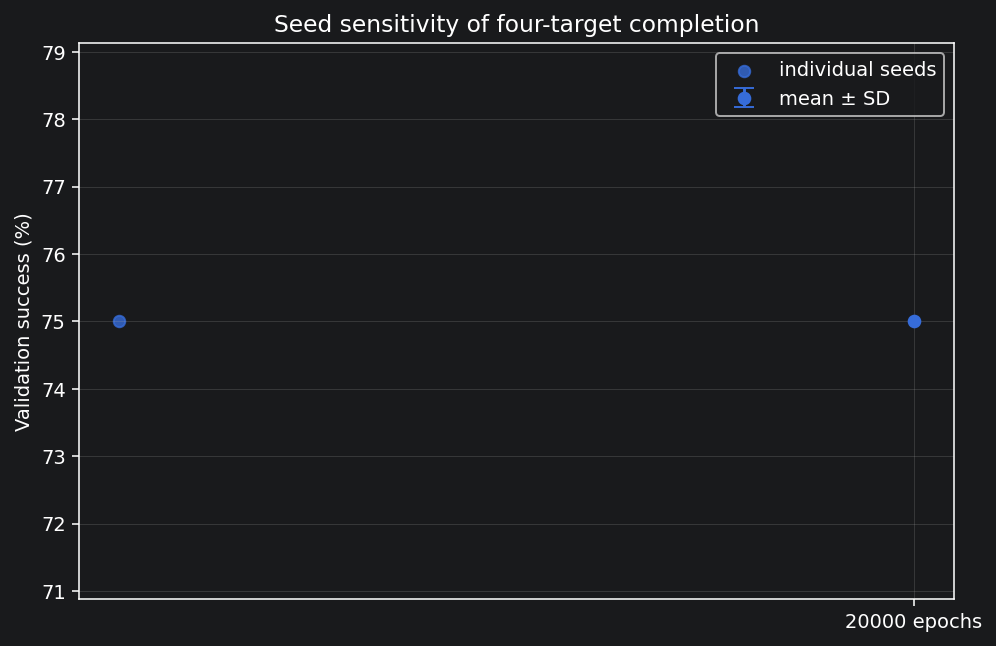

Saved: /home/matcho/projects/streaming-flow-policy/experiments/four_boxes_experiments/four_targets/runs/conditional_mlp_canonical_fresh_002/seed_sensitivity_success.png


In [9]:
fig, ax = plt.subplots(
    figsize=(7, 4.5),
    dpi=140,
    constrained_layout=True,
)

x = np.arange(len(BUDGETS))

means = np.array([
    100 * aggregate[budget]["success"][0]
    for budget in BUDGETS
])
stds = np.array([
    100 * aggregate[budget]["success"][1]
    for budget in BUDGETS
])

ax.errorbar(
    x,
    means,
    yerr=stds,
    fmt="o",
    capsize=5,
    label="mean ± SD",
)

for i, budget in enumerate(BUDGETS):
    ys = [
        100
        * seed_results[(budget, seed)]["Validation"]["all_visited_rate"]
        for seed in SEEDS
    ]
    jitter = np.linspace(-0.06, 0.06, len(SEEDS))
    ax.scatter(
        np.full(len(SEEDS), x[i]) + jitter,
        ys,
        s=35,
        alpha=0.8,
        label="individual seeds" if i == 0 else None,
    )

ax.set_xticks(x)
ax.set_xticklabels([
    f"{budget} epochs"
    for budget in BUDGETS
])
ax.set_ylabel("Validation success (%)")
ax.set_title(
    "Seed sensitivity of four-target completion"
)
ax.grid(alpha=0.2)
ax.legend()

figure_path = SWEEP_ROOT / "seed_sensitivity_success.png"
fig.savefig(
    figure_path,
    dpi=180,
)
plt.show()

print("Saved:", figure_path)


In [10]:
# ============================================================
# Final evaluation on the untouched TEST set
# ============================================================

from pathlib import Path
import subprocess
import numpy as np
import torch
from torch import nn


# ============================================================
# Settings
# ============================================================

EVAL_STEPS = 1000
VISIT_TOLERANCE = 0.02

# Add 20000 here if you want to test it too.
BUDGETS_TO_TEST = list(BUDGETS)
SEEDS_TO_TEST = list(SEEDS)


# ============================================================
# Automatically locate project root
# ============================================================

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    start = start.expanduser().resolve()

    try:
        result = subprocess.run(
            ["git", "-C", str(start), "rev-parse", "--show-toplevel"],
            check=True,
            capture_output=True,
            text=True,
        )
        return Path(result.stdout.strip()).resolve()
    except Exception:
        pass

    for candidate in [start, *start.parents]:
        if (
            (candidate / "pyproject.toml").exists()
            and (
                candidate
                / "experiments"
                / "four_boxes_experiments"
                / "four_targets"
            ).exists()
        ):
            return candidate

    raise RuntimeError("Could not locate project root.")


PROJECT_ROOT = find_project_root()

TASK_ROOT = (
    PROJECT_ROOT
    / "experiments"
    / "four_boxes_experiments"
    / "four_targets"
)

DATASET_DIR = TASK_ROOT / "datasets" / "v1"

# Keep SWEEP_ROOT from the settings cell; do not change training output here.

SWEEP_20000_ROOT = (
    TASK_ROOT
    / "runs"
    / "conditional_mlp_canonical_seed_sweep_20000"
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Project root:", PROJECT_ROOT)
print("Device:", DEVICE)


# ============================================================
# Load TEST split
# ============================================================

test_path = DATASET_DIR / "test.npz"

if not test_path.exists():
    raise FileNotFoundError(
        f"Test split not found:\n{test_path}"
    )

with np.load(test_path, allow_pickle=False) as archive:
    test_split = {
        key: archive[key].copy()
        for key in archive.files
    }

print("Test layouts:", len(test_split["targets"]))


# ============================================================
# Model definition
# Must exactly match training
# ============================================================

def canonicalize_box_inputs(inputs):
    boxes = inputs[:, 5:].reshape(-1, 4, 2)

    # secondary y key, then primary x key
    for coordinate in [1, 0]:
        order = torch.argsort(
            boxes[:, :, coordinate],
            dim=1,
            stable=True,
        )

        boxes = torch.gather(
            boxes,
            1,
            order.unsqueeze(-1).expand(-1, -1, 2),
        )

    return torch.cat(
        [
            inputs[:, :5],
            boxes.reshape(-1, 8),
        ],
        dim=1,
    )


class CanonicalConditionalVelocityMLP(nn.Module):
    def __init__(self):
        super().__init__()

        layers = []
        width = 13

        for _ in range(4):
            layers.extend([
                nn.Linear(width, 128),
                nn.SiLU(),
            ])
            width = 128

        layers.append(
            nn.Linear(width, 2)
        )

        self.network = nn.Sequential(*layers)

    def forward(self, inputs):
        return self.network(
            2.0 * canonicalize_box_inputs(inputs) - 1.0
        )


# ============================================================
# Rollout helper
# ============================================================

@torch.no_grad()
def generate_paths(model, split, num_steps=1000):
    parameter = next(model.parameters())

    conditions = torch.as_tensor(
        split["conditions"],
        dtype=parameter.dtype,
        device=parameter.device,
    )

    actions = torch.as_tensor(
        split["starts"],
        dtype=parameter.dtype,
        device=parameter.device,
    ).clone()

    model.eval()

    paths = [
        actions.cpu().numpy().copy()
    ]

    dt = 1.0 / num_steps

    def velocity(a, tau):
        t = torch.full(
            (len(a), 1),
            tau,
            dtype=a.dtype,
            device=a.device,
        )

        return model(
            torch.cat(
                [a, t, conditions],
                dim=1,
            )
        )

    for step in range(num_steps):
        tau = step * dt

        k1 = velocity(
            actions,
            tau,
        )

        k2 = velocity(
            actions + dt * k1 / 2,
            tau + dt / 2,
        )

        k3 = velocity(
            actions + dt * k2 / 2,
            tau + dt / 2,
        )

        k4 = velocity(
            actions + dt * k3,
            min(tau + dt, 1.0),
        )

        actions = (
            actions
            + dt / 6.0
            * (
                k1
                + 2 * k2
                + 2 * k3
                + k4
            )
        )

        if not torch.isfinite(actions).all():
            raise RuntimeError(
                f"Non-finite rollout at step {step}"
            )

        paths.append(
            actions.cpu().numpy().copy()
        )

    return np.stack(
        paths,
        axis=1,
    )


# ============================================================
# Distance from each target to the generated polyline
# ============================================================

def target_distances(path, targets):
    p0 = path[:-1]
    vectors = np.diff(
        path,
        axis=0,
    )

    offsets = (
        targets[:, None, :]
        - p0[None, :, :]
    )

    denominator = np.maximum(
        np.sum(
            vectors ** 2,
            axis=1,
        ),
        1e-30,
    )

    fraction = np.clip(
        np.sum(
            offsets * vectors[None, :, :],
            axis=-1,
        )
        / denominator[None, :],
        0,
        1,
    )

    nearest = (
        p0[None, :, :]
        + fraction[:, :, None]
        * vectors[None, :, :]
    )

    return np.linalg.norm(
        targets[:, None, :]
        - nearest,
        axis=-1,
    ).min(axis=1)


# ============================================================
# Resolve checkpoint path
# ============================================================

def checkpoint_path_for(budget, seed):
    # Use the actual directory returned by training, including skipped old runs.
    record = globals().get("run_records", {}).get((budget, seed))
    if record is not None:
        name = "best_completion.pt" if CHECKPOINT_SELECTION == "completion" else "best.pt"
        return Path(record["run_dir"]) / name
    config = make_run_config(budget, seed)
    for directory in checkpoint_directories(seed):
        if completed_checkpoint(directory, budget, config) is not None:
            name = "best_completion.pt" if CHECKPOINT_SELECTION == "completion" else "best.pt"
            return directory / name
    name = "best_completion.pt" if CHECKPOINT_SELECTION == "completion" else "best.pt"
    return SWEEP_ROOT / f"budget_{budget}_seed_{seed}" / name


# ============================================================
# Evaluate all models
# ============================================================

test_results = {}

for budget in BUDGETS_TO_TEST:

    for seed in SEEDS_TO_TEST:

        ckpt_path = checkpoint_path_for(
            budget,
            seed,
        )

        if not ckpt_path.exists():
            print(
                f"[skip] Missing checkpoint: "
                f"{budget} epochs, seed {seed}"
            )
            continue

        checkpoint = torch.load(
            ckpt_path,
            map_location="cpu",
            weights_only=True,
        )

        model = (
            CanonicalConditionalVelocityMLP()
            .to(
                device=DEVICE,
                dtype=torch.float64,
            )
        )

        model.load_state_dict(
            checkpoint["model"],
            strict=True,
        )

        model.eval()

        print(
            f"\nEvaluating "
            f"{budget} epochs, seed {seed} "
            f"(selected epoch {checkpoint['epoch']})..."
        )

        paths = generate_paths(
            model,
            test_split,
            EVAL_STEPS,
        )

        distances = np.stack([
            target_distances(
                path,
                targets,
            )
            for path, targets
            in zip(
                paths,
                test_split["targets"],
            )
        ])

        order_summary, order_details = four_target_path_metrics(
            paths, test_split, VISIT_TOLERANCE,
            optimal_rtol=MONITOR["optimal_order_rtol"])
        counts = order_details["visited_counts"]

        success_rate = float(
            np.mean(counts == 4)
        )

        mean_visited = float(
            counts.mean()
        )

        mean_worst_distance = float(
            distances.max(
                axis=1
            ).mean()
        )

        histogram = np.bincount(
            counts,
            minlength=5,
        )

        test_results[
            (budget, seed)
        ] = {
            "success_rate":
                success_rate,

            "optimal_order_success_rate": order_summary["optimal_order_success_percent"] / 100.,
            "mean_visited":
                mean_visited,

            "mean_worst_distance":
                mean_worst_distance,

            "histogram":
                histogram,

            "selected_epoch":
                checkpoint["epoch"],
        }

        print(
            f"  Success: "
            f"{success_rate:.1%}"
        )

        print(f"  Completion + optimal first-visit order: "
              f"{order_summary['optimal_order_success_percent']:.2f}%")
        print(
            f"  Mean visited: "
            f"{mean_visited:.2f}/4"
        )

        print(
            f"  Mean worst-target distance: "
            f"{mean_worst_distance:.6f}"
        )

        print(
            f"  Visit histogram [0,1,2,3,4]: "
            f"{histogram.tolist()}"
        )

        del model

        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()


# ============================================================
# Per-model table
# ============================================================

print("\n")
print(
    f"{'Budget':>8} "
    f"{'Seed':>6} "
    f"{'Epoch':>8} "
    f"{'Success':>10} "
    f"{'Mean visited':>14} "
    f"{'Worst dist':>12}"
)

print("-" * 66)

for budget in BUDGETS_TO_TEST:

    for seed in SEEDS_TO_TEST:

        key = (
            budget,
            seed,
        )

        if key not in test_results:
            continue

        r = test_results[key]

        print(
            f"{budget:>8} "
            f"{seed:>6} "
            f"{r['selected_epoch']:>8} "
            f"{100*r['success_rate']:>9.1f}% "
            f"{r['mean_visited']:>12.2f}/4 "
            f"{r['mean_worst_distance']:>12.6f}"
        )


# ============================================================
# Mean ± SD across seeds
# ============================================================

print("\nAcross-seed TEST summary")
print("=" * 60)

for budget in BUDGETS_TO_TEST:

    rates = [
        test_results[
            (budget, seed)
        ]["success_rate"]
        for seed in SEEDS_TO_TEST
        if (
            budget,
            seed,
        ) in test_results
    ]

    if len(rates) == 0:
        continue

    rates = np.asarray(
        rates,
        dtype=float,
    )

    mean = rates.mean()

    if len(rates) > 1:
        std = rates.std(
            ddof=1
        )
    else:
        std = 0.0

    optimal_rates = np.asarray([test_results[(budget, seed)]["optimal_order_success_rate"]
                                for seed in SEEDS_TO_TEST if (budget, seed) in test_results])
    optimal_mean = float(optimal_rates.mean())
    optimal_sd = float(optimal_rates.std(ddof=1)) if len(optimal_rates) > 1 else 0.
    print(f"{budget:>5} epochs: optimal-order success "
          f"{100*optimal_mean:.2f}% ± {100*optimal_sd:.2f} pp")
    print(
        f"{budget:>5} epochs: "
        f"{100*mean:.2f}% "
        f"± {100*std:.2f} pp "
        f"(n={len(rates)})"
    )

Project root: /home/matcho/projects/streaming-flow-policy
Device: cuda
Test layouts: 1000

Evaluating 20000 epochs, seed 0 (selected epoch 15250)...
  Success: 66.7%
  Completion + optimal first-visit order: 66.70%
  Mean visited: 3.50/4
  Mean worst-target distance: 0.032307
  Visit histogram [0,1,2,3,4]: [5, 31, 95, 202, 667]


  Budget   Seed    Epoch    Success   Mean visited   Worst dist
------------------------------------------------------------------
   20000      0    15250      66.7%         3.50/4     0.032307

Across-seed TEST summary
20000 epochs: optimal-order success 66.70% ± 0.00 pp
20000 epochs: 66.70% ± 0.00 pp (n=1)
